In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
import sqlite3
from scipy.stats import ttest_ind
import scipy.stats as stats

conn = sqlite3.connect('inventory.db')

In [2]:
df = pd.read_sql_query("select * from vendor_sales_summary",conn)
df.head()

,VendorNumber,VendorName,Brand,Description,PurchasePrice,ActualPrice,Volume,TotalPurchaseQuantity,TotalPurchaseDollars,TotalSalesQuantity,TotalSalesDollars,TotalSalesPrice,TotalExciseTax,FreightCost,GrossProfit,profitMargin,StockTurnover,SalestoPurchaseRatio
0,1128,BROWN-FORMAN CORP,1233,Jack Daniels No 7 Black,26.27,36.99,1750.0,145080,3811251.60,97457.0,3500975.43,490835.48,179065.67,68601.68,-310276.17,-8.862563,0.671747,0.918589
1,4425,MARTIGNETTI COMPANIES,3405,Tito's Handmade Vodka,23.19,28.99,1750.0,164038,3804041.22,110975.0,3345756.21,408883.80,203905.77,144929.24,-458285.01,-13.697502,0.676520,0.879527
2,17035,PERNOD RICARD USA,8068,Absolut 80 Proof,18.24,24.99,1750.0,187407,3418303.68,135702.0,3300314.98,339246.64,249341.03,123780.22,-117988.70,-3.575074,0.724103,0.965483
3,3960,DIAGEO NORTH AMERICA INC,4261,Capt Morgan Spiced Rum,16.17,22.99,1750.0,201682,3261197.94,120554.0,2749231.46,304727.98,221507.91,257032.07,-511966.48,-18.622167,0.597743,0.843013
4,3960,DIAGEO NORTH AMERICA INC,3545,Ketel One Vodka,21.89,29.99,1750.0,138109,3023206.01,92294.0,2882450.06,394891.92,169579.73,257032.07,-140755.95,-4.883205,0.668269,0.953441


In [3]:
df.shape

(10692, 18)

In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
VendorNumber,10692.0,1.065065e+04,18753.519148,2.00,3951.000000,7153.000000,9552.000000,2.013590e+05
Brand,10692.0,1.803923e+04,12662.187074,58.00,5793.500000,18761.500000,25514.250000,9.063100e+04
PurchasePrice,10692.0,2.438530e+01,109.269375,0.36,6.840000,10.455000,19.482500,5.681810e+03
ActualPrice,10692.0,3.564367e+01,148.246016,0.49,10.990000,15.990000,28.990000,7.499990e+03
Volume,10692.0,8.473605e+02,664.309212,50.00,750.000000,750.000000,750.000000,2.000000e+04
TotalPurchaseQuantity,10692.0,3.140887e+03,11095.086769,1.00,36.000000,262.000000,1975.750000,3.376600e+05
TotalPurchaseDollars,10692.0,3.010669e+04,123067.799627,0.71,453.457500,3655.465000,20738.245000,3.811252e+06
TotalSalesQuantity,10692.0,2.101461e+03,7637.392326,0.00,17.000000,150.000000,1244.250000,2.389330e+05
TotalSalesDollars,10692.0,2.863991e+04,114834.596975,0.00,351.862500,3230.325000,18928.747500,3.500975e+06
TotalSalesPrice,10692.0,1.297921e+04,31980.704665,0.00,118.595000,1679.160000,10636.140000,4.908355e+05


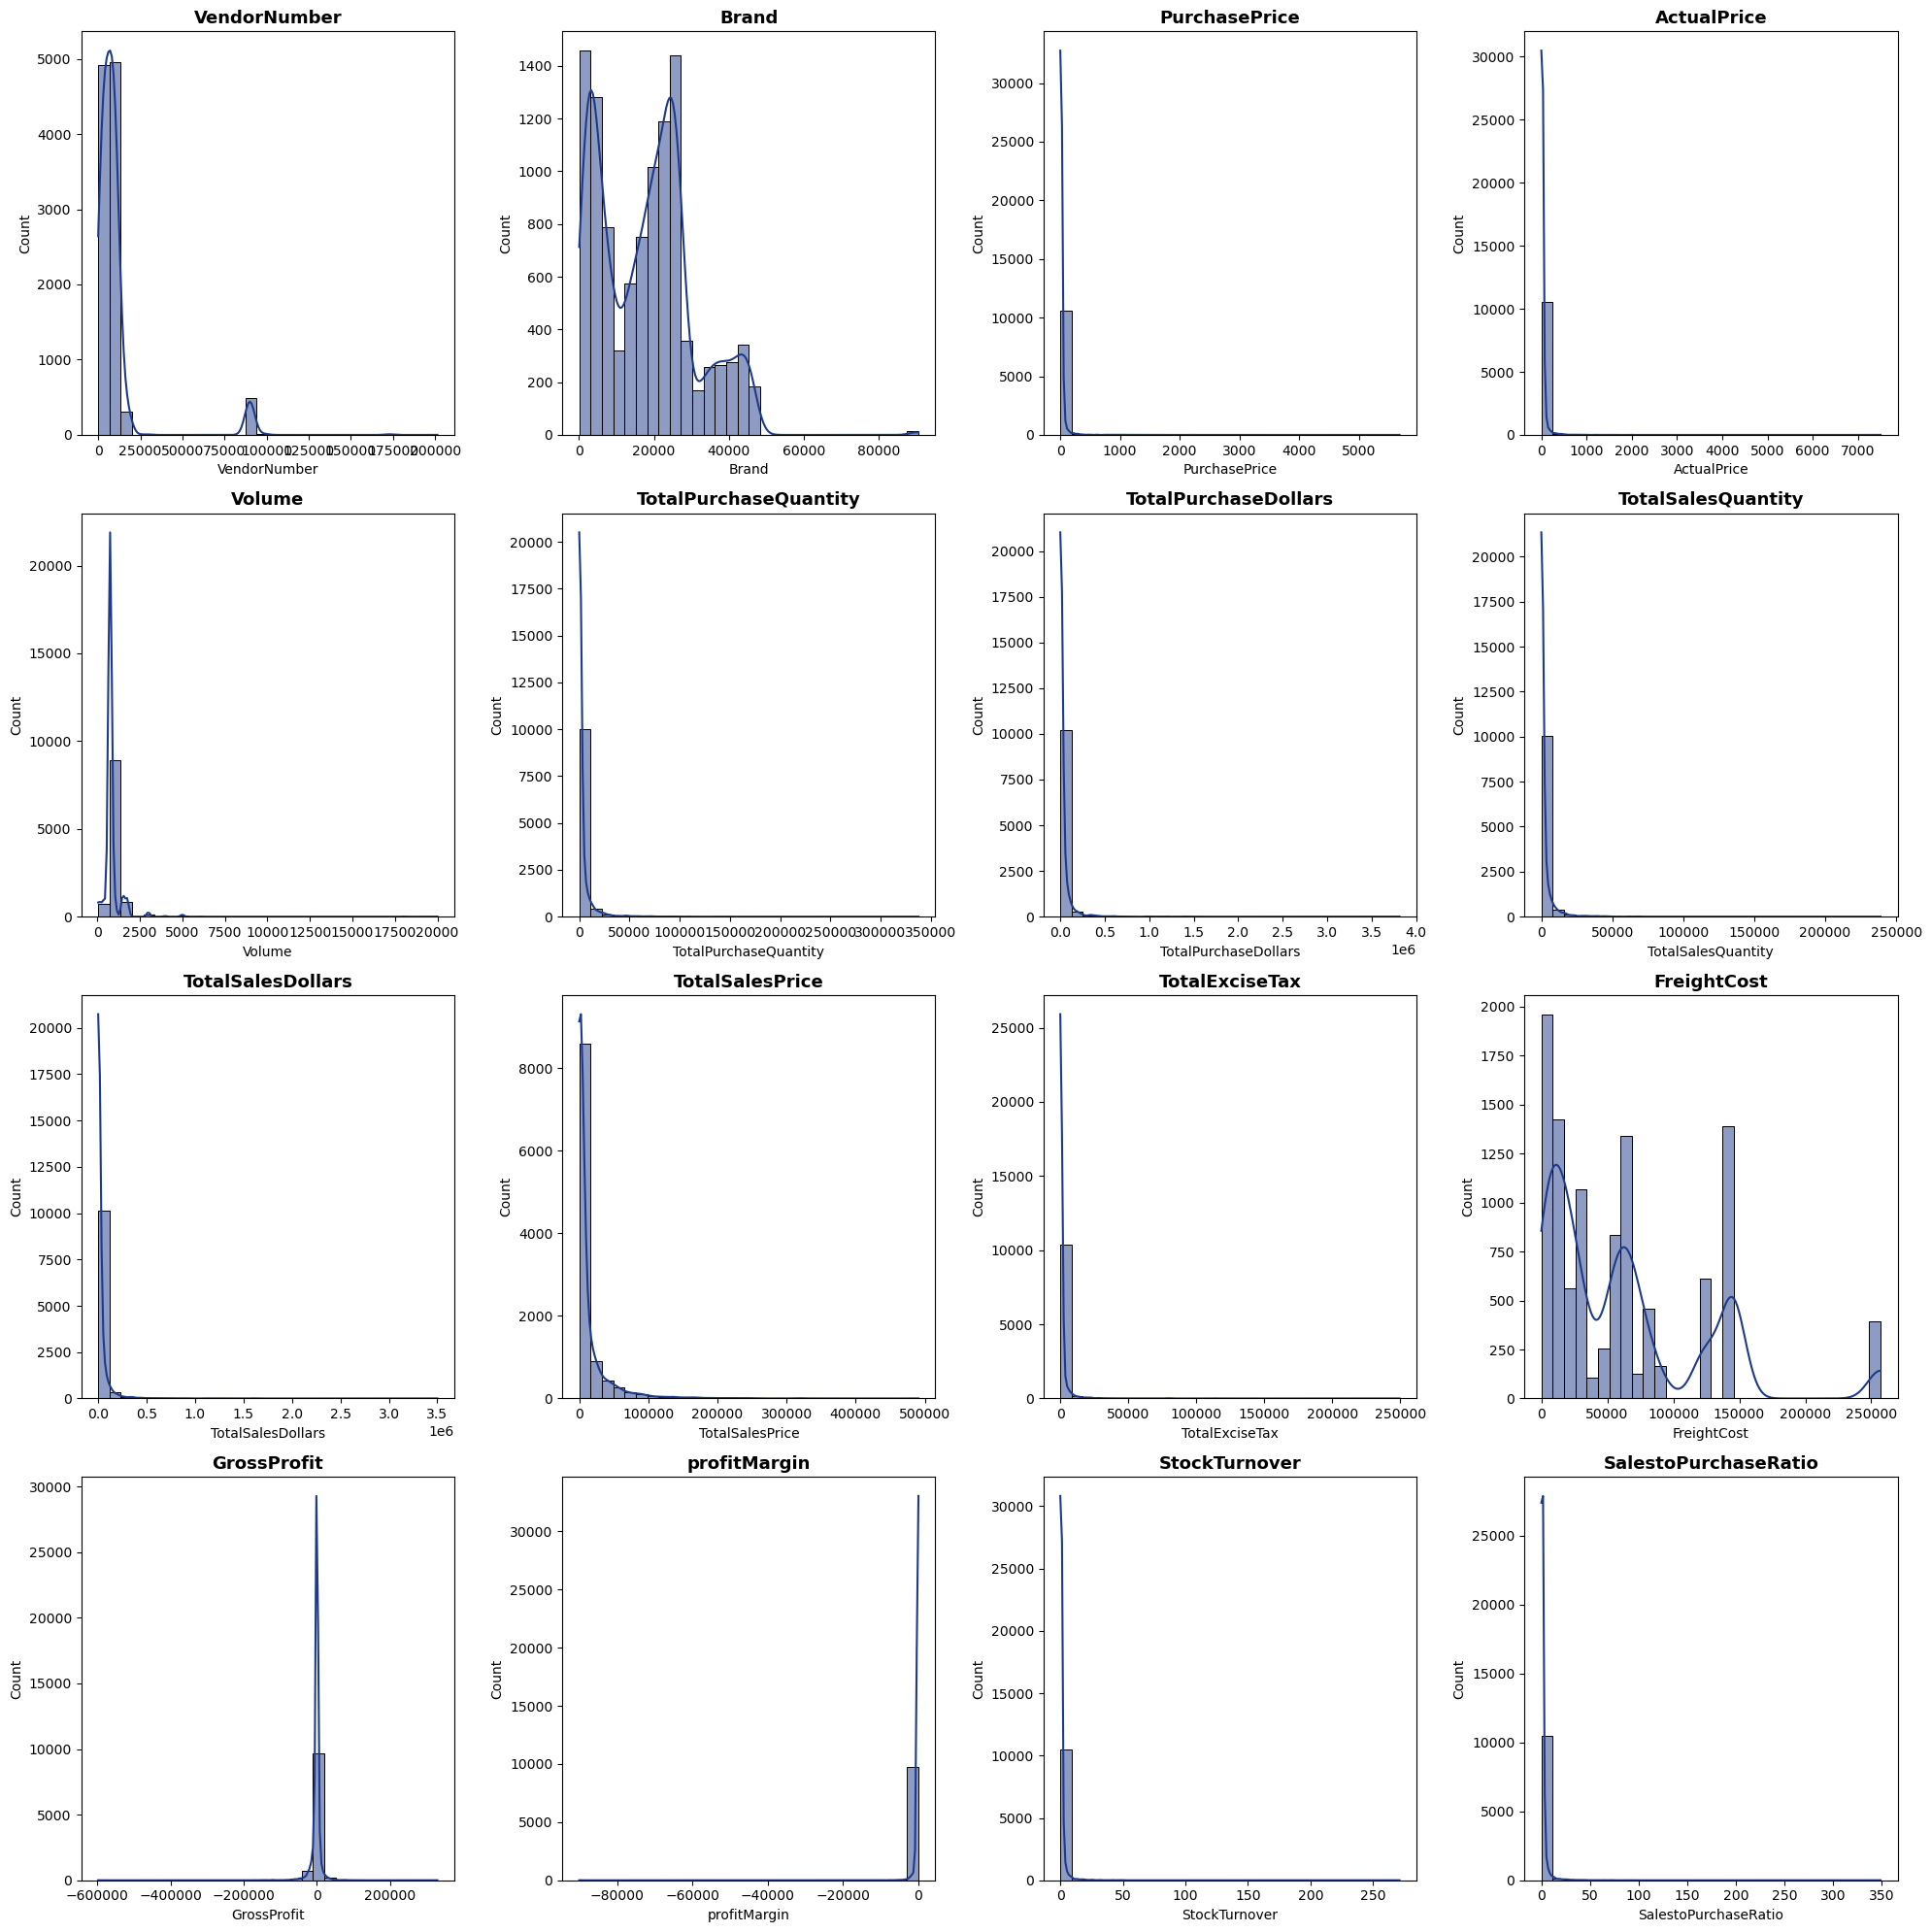

In [4]:
#Distribution PLots for numerical Columns:
numerical_cols = df.select_dtypes(include = np.number).columns

plt.figure(figsize =(20,20))
for i , col in enumerate(numerical_cols):
    plt.subplot(4,4,i+1)
    sns.histplot(df[col],kde=True,bins=30,color='#1E3A8A')
    plt.title(col, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

##### Most products have low sales and purchases, but a few products or vendors contribute extremely high values.
##### Vendors and brands can be divided into different groups, such as major suppliers and smaller suppliers.
##### Freight costs vary because different vendors and shipments have different shipping conditions.

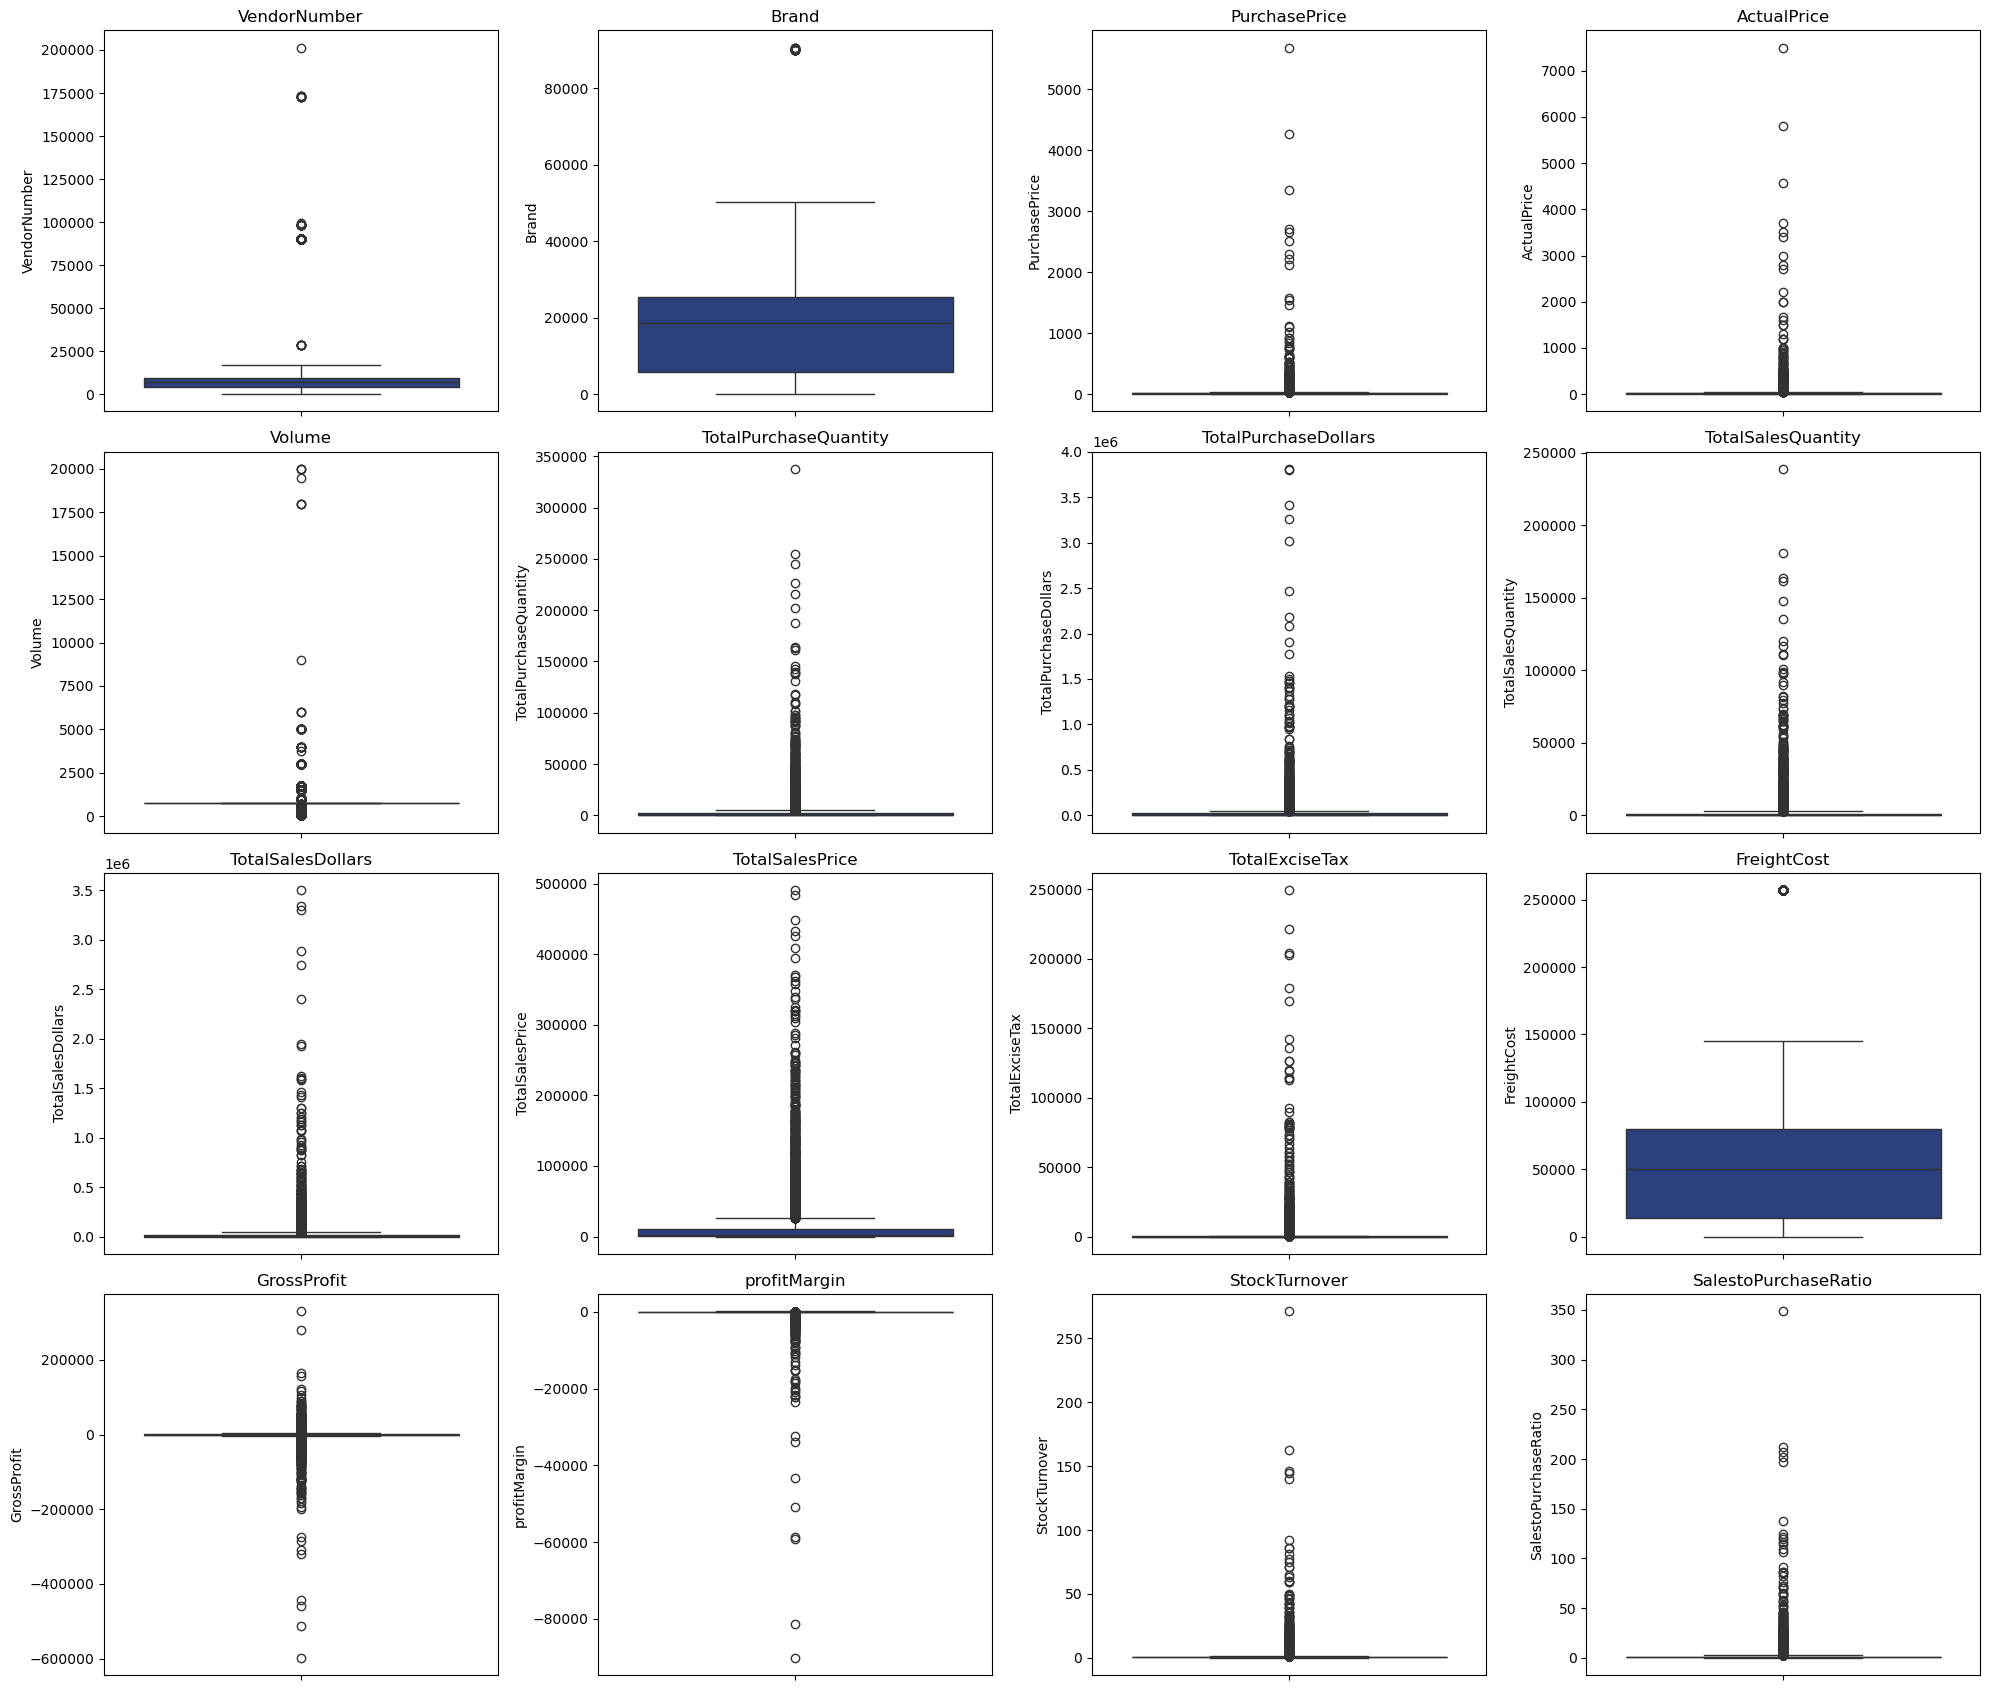

In [5]:
plt.figure(figsize=(20,17))
for i,col in enumerate(numerical_cols):
    plt.subplot(4,4,i+1)
    sns.boxplot(y=df[col],color='#1E3A8A')
    plt.title(col)
plt.tight_layout()
plt.show()

In [4]:
#Let's filter the data by removing inconistences
df = pd.read_sql_query("""SELECT *FROM vendor_sales_summary WHERE GrossProfit > 0 AND ProfitMargin >0 AND TotalSalesQuantity > 0 """,conn)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
VendorNumber,5181.0,9633.474233,16730.920539,2.000000,3252.000000,7153.000000,9552.000000,2.013590e+05
Brand,5181.0,18847.255163,12944.146920,61.000000,6918.000000,19000.000000,25090.000000,9.060900e+04
PurchasePrice,5181.0,22.642615,77.436738,0.360000,6.490000,9.390000,16.770000,3.352930e+03
ActualPrice,5181.0,34.305690,111.332629,0.490000,9.990000,14.990000,24.990000,4.559990e+03
Volume,5181.0,870.086373,661.318078,50.000000,750.000000,750.000000,750.000000,2.000000e+04
TotalPurchaseQuantity,5181.0,2773.629415,7962.260989,1.000000,24.000000,239.000000,2081.000000,2.156680e+05
TotalPurchaseDollars,5181.0,22156.329388,73341.307339,0.710000,359.820000,2889.200000,16901.780000,1.903740e+06
TotalSalesQuantity,5181.0,2101.053658,5756.608028,1.000000,41.000000,293.000000,1641.000000,1.479130e+05
TotalSalesDollars,5181.0,26135.872880,80045.505310,4.990000,1034.550000,5069.750000,20905.950000,1.922581e+06
TotalSalesPrice,5181.0,11793.073322,25242.111053,0.980000,430.090000,2625.920000,11324.160000,4.837874e+05


In [5]:
df.shape

(5181, 18)

In [7]:
df.to_csv("vendor_sales_cleaned.csv", index=False)

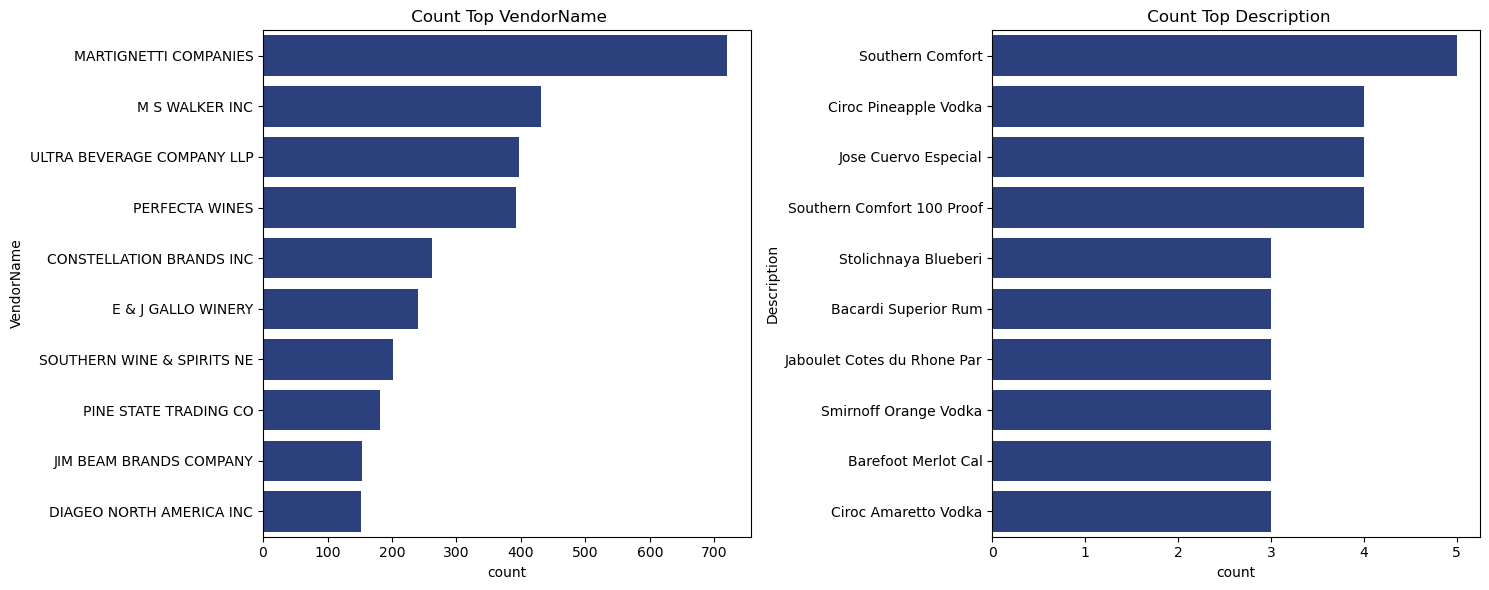

In [6]:
categorical_cols = ['VendorName','Description']
plt.figure(figsize =(15,6))
for i, col in enumerate(categorical_cols):
    plt.subplot(1,2,i+1)
    sns.countplot(y=df[col],order=df[col].value_counts().index[:10],color='#1E3A8A')
    plt.title(f" Count Top {col }")
plt.tight_layout()
plt.show()


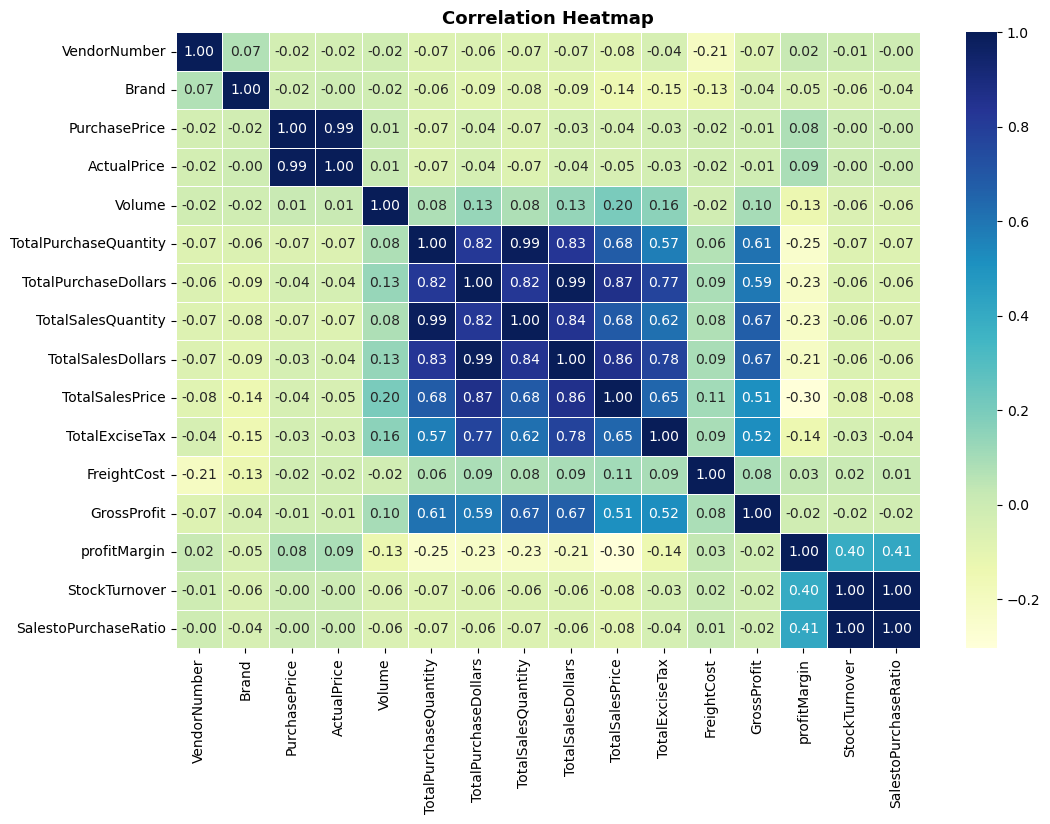

In [8]:
# Identifying the relationship
plt.figure(figsize=(12,8))
correlation_matrix = df[numerical_cols].corr()
sns.heatmap(correlation_matrix,annot = True ,fmt='.2f',cmap="YlGnBu",linewidth = 0.5)
plt.title("Correlation Heatmap", fontsize=13, fontweight='bold')
plt.show()

In [9]:
#To identify underperforming brands that require promotional or pricing adjustments.
brand=df.groupby('Description').agg({'TotalSalesDollars':'sum','profitMargin':'mean'}).reset_index()
brand

,Description,TotalSalesDollars,profitMargin
0,10 Span Chard CC,2778.79,13.601244
1,10 Span Pnt Gris Monterey Cy,1805.09,21.821073
2,10 Span Pnt Nr CC,1879.99,3.675551
3,12 Days of Pearls Gift Set,309.69,97.678323
4,13 Celsius Svgn Bl,22343.90,35.509647
...,...,...,...
4893,Zion Dolev Muscato,1230.88,70.047446
4894,Zonin Moscato,239.76,18.318318
4895,Zorah Red,417.81,67.559417
4896,Zum Rsl,7714.28,5.244559


In [10]:
low_sale_threshold = brand['TotalSalesDollars'].quantile(0.15)
high_profit_threshold = brand['profitMargin'].quantile(0.85)
Target_brand = brand[(brand['TotalSalesDollars'] <= low_sale_threshold )& (brand['profitMargin'] >=high_profit_threshold)]
print("Brands with low sales but hight Profit")
display(Target_brand.sort_values('TotalSalesDollars'))
          

Brands with low sales but hight Profit


,Description,TotalSalesDollars,profitMargin
1448,Concannon Glen Ellen Wh Zin,15.95,83.448276
1524,Crown Royal Apple,23.88,88.107203
3967,Sauza Sprklg Wild Berry Marg,27.96,82.153076
4583,Tracia Syrah,44.94,88.495772
387,Basilica Amaretto,47.45,85.079031
...,...,...,...
1196,Ch Reserve d La Cometesse 11,459.90,93.150685
2820,Lincourt Courtney's Chard,461.58,76.342129
34,A Bichot Ch Gris Nuits St Ge,471.92,91.379895
1058,Ch Haut Bages Liberal Paulic,476.91,77.171793


In [12]:
high_profit_threshold

np.float64(74.73433941628421)

In [11]:
brand_perfromance = brand[brand['TotalSalesDollars'] < 10000]

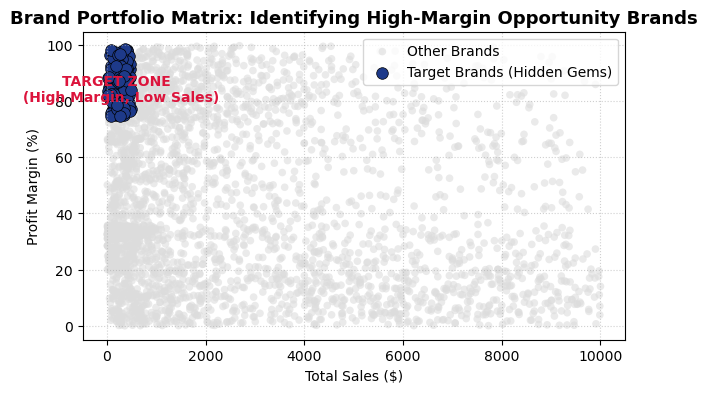

In [12]:
plt.figure(figsize = (7,4))
sns.scatterplot(
    data=brand_perfromance, 
    x='TotalSalesDollars', 
    y='profitMargin', 
    color='gainsboro', 
    edgecolor='none',
    alpha=0.6, 
    s=30,
    label='Other Brands'
)
sns.scatterplot(
    data=Target_brand, 
    x='TotalSalesDollars', 
    y='profitMargin', 
    color='#1E3A8A',  # Amber highlight
    edgecolor='black',
    linewidth=0.5,
    s=70, 
    label='Target Brands (Hidden Gems)'
)
plt.text(
    x=low_sale_threshold / 2, 
    y=high_profit_threshold + 5, 
    s="TARGET ZONE \n (High Margin, Low Sales)", 
    fontsize=10, 
    fontweight='bold', 
    color='crimson',
    ha='center'
)

plt.title("Brand Portfolio Matrix: Identifying High-Margin Opportunity Brands", fontsize=13, fontweight='bold')
plt.xlabel("Total Sales ($)")
plt.ylabel("Profit Margin (%)")
plt.legend(frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)

In [13]:
#To determine the Top-Perfromance Vendors Contributing to Sales and gross profit.
Top_vendors = df.groupby('VendorName')["TotalSalesDollars"].sum().nlargest(10)
Top_Brand = df.groupby('Description')["TotalSalesDollars"].sum().nlargest(10)

def format_dollar(value):
    if value >= 1_00_000:
        return f"{value /1_00_000:.2f}M"
    elif value >=1_000:
        return f"{value / 1_000:.2f}K"
    else:
        return str(value)
Top_Brand.apply(lambda x: format_dollar(x))

Description
Tanqueray                       21.95M
Bombay Sapphire Gin             18.69M
Jose Cuervo Especial            18.47M
Kendall Jackson Chard Vt RSV    16.24M
Capt Morgan Original Barrel     15.97M
Patron Silver Tequila           15.10M
Bacardi Superior Rum Trav       15.06M
Three Olives Vodka              12.72M
Clos du Bois Chard               9.02M
Jack Daniels No 7 Black          8.81M
Name: TotalSalesDollars, dtype: object

In [14]:
Top_vendors.apply(lambda x: format_dollar(x))

VendorName
MARTIGNETTI COMPANIES         152.00M
CONSTELLATION BRANDS INC      126.39M
DIAGEO NORTH AMERICA INC      113.48M
E & J GALLO WINERY             76.57M
ULTRA BEVERAGE COMPANY LLP     69.51M
BACARDI USA INC                67.69M
PROXIMO SPIRITS INC.           66.68M
M S WALKER INC                 60.76M
WINE GROUP INC                 54.87M
JIM BEAM BRANDS COMPANY        53.15M
Name: TotalSalesDollars, dtype: object

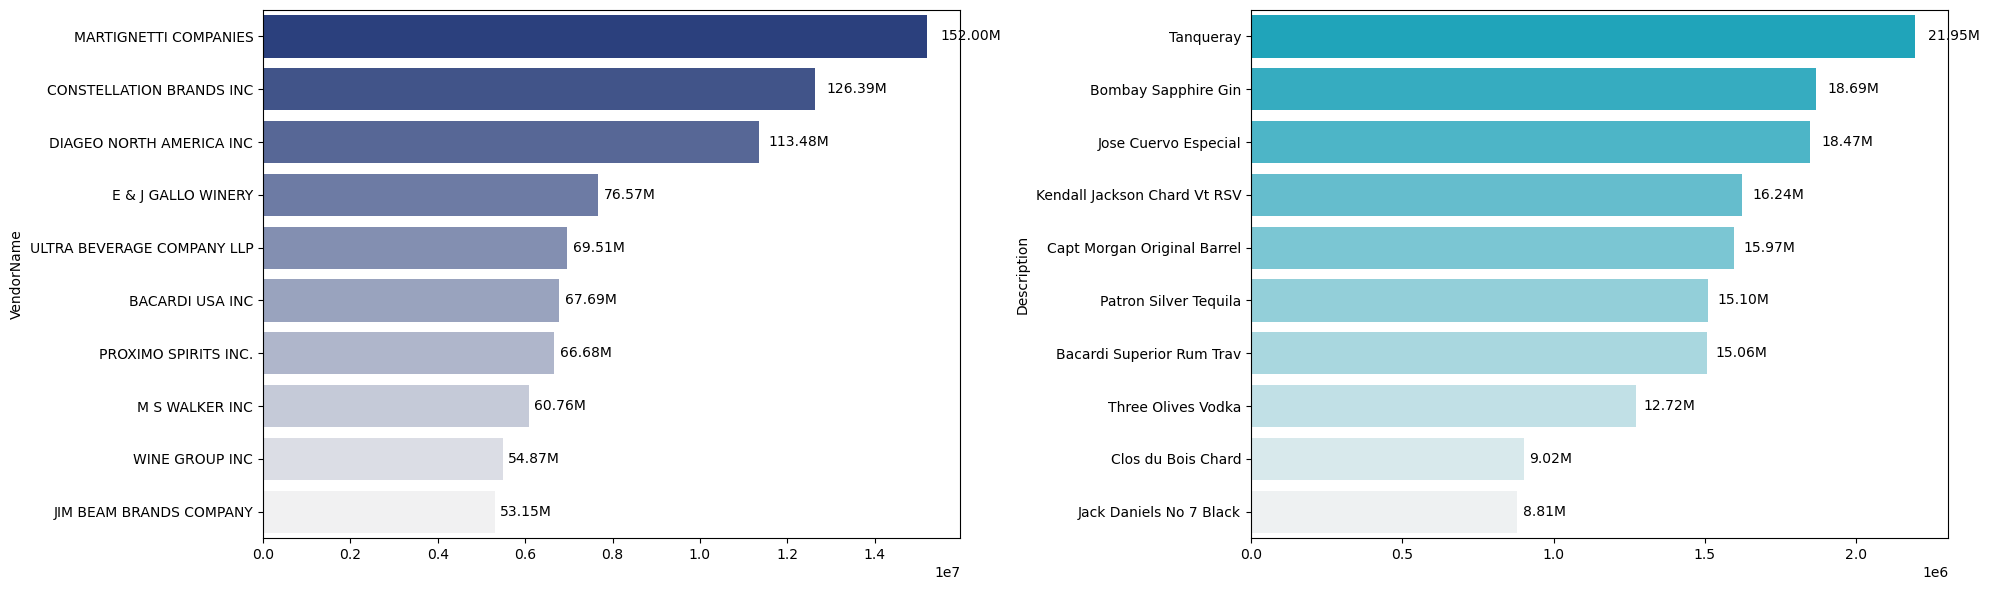

In [18]:
plt.figure(figsize = (20,6))

blue_palette = sns.light_palette("#1E3A8A", n_colors=len(Top_vendors), reverse=True)
brand_palette = sns.light_palette("#06B6D4", n_colors=len(Top_Brand), reverse=True)

plt.subplot(1,2,1)
ax1 = sns.barplot(y=Top_vendors.index,x=Top_vendors.values,palette=blue_palette)

for bar in ax1.patches:
    ax1.text(bar.get_width()+(bar.get_width()*0.02),
             bar.get_y() +bar.get_height()/2,
             format_dollar(bar.get_width()),
             ha='left',va='center',fontsize = 10 ,color= 'black')
plt.subplot(1,2,2)
ax2 = sns.barplot(y=Top_Brand.index,x=Top_Brand.values,palette=brand_palette)

for bar in ax2.patches:
    ax2.text(bar.get_width()+(bar.get_width()*0.02),
             bar.get_y() +bar.get_height()/2,
             format_dollar(bar.get_width()),
             ha='left',va='center',fontsize = 10 ,color='black')

plt.tight_layout()
plt.show()
    

In [19]:
vendor_performance = df.groupby('VendorName').agg({
    'TotalPurchaseDollars':'sum',
    'GrossProfit':'sum',
    'TotalSalesDollars':'sum'
}).reset_index()

In [20]:
vendor_performance

,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars
0,ALISA CARR BEVERAGES,25698.12,53340.47,79038.59
1,AMERICAN SPIRITS EXCHANGE,934.08,271.25,1205.33
2,ATLANTIC IMPORTING COMPANY,3230.68,7722.41,10953.09
3,BACARDI USA INC,5781519.35,987953.26,6769472.61
4,BANFI PRODUCTS CORP,1322953.15,253940.09,1576893.24
...,...,...,...,...
96,VRANKEN AMERICA,52884.90,38605.80,91490.70
97,WEIN BAUER INC,605.52,59.88,665.40
98,WESTERN SPIRITS BEVERAGE CO,24178.13,28834.34,53012.47
99,WILLIAM GRANT & SONS INC,975108.95,70587.61,1045696.56


In [21]:
vendor_performance['Purchase_Contribution%'] = vendor_performance['TotalPurchaseDollars']/vendor_performance['TotalPurchaseDollars'].sum() * 100

In [22]:
# round(vendor_performance.sort_values('Purchase_Contribution%',ascending=False),2)
vendor_performance = round(vendor_performance.sort_values(by="Purchase_Contribution%", ascending=False),2)

In [23]:
Top_vendors = vendor_performance.head(10)
dollar_cols = ['TotalSalesDollars', 'TotalPurchaseDollars', 'GrossProfit']
Top_vendors[dollar_cols] = Top_vendors[dollar_cols].applymap(format_dollar)
Top_vendors

,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars,Purchase_Contribution%
48,MARTIGNETTI COMPANIES,120.45M,31.55M,152.00M,10.49
16,CONSTELLATION BRANDS INC,107.06M,19.34M,126.39M,9.33
21,DIAGEO NORTH AMERICA INC,102.61M,10.87M,113.48M,8.94
25,E & J GALLO WINERY,65.82M,10.75M,76.57M,5.73
64,PROXIMO SPIRITS INC.,60.74M,5.94M,66.68M,5.29
3,BACARDI USA INC,57.82M,9.88M,67.69M,5.04
91,ULTRA BEVERAGE COMPANY LLP,55.78M,13.73M,69.51M,4.86
45,M S WALKER INC,50.57M,10.19M,60.76M,4.41
100,WINE GROUP INC,47.29M,7.58M,54.87M,4.12
38,JIM BEAM BRANDS COMPANY,46.64M,6.51M,53.15M,4.06


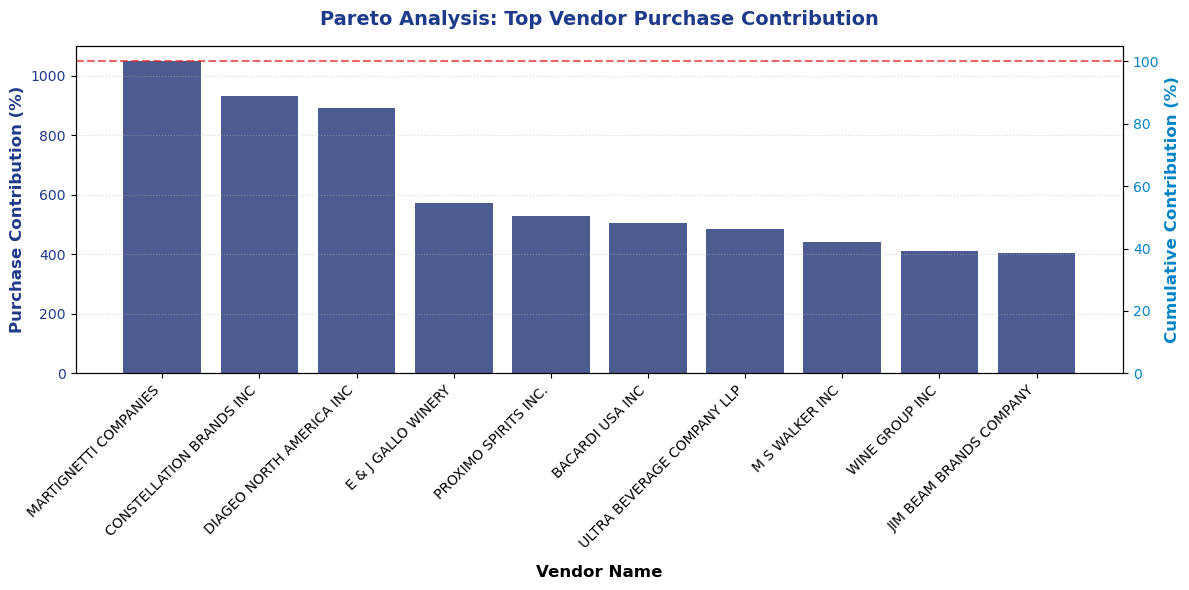

In [24]:
# 1. Sort vendor data by Purchase Contribution descending
vendor_sorted = vendor_performance.sort_values("Purchase_Contribution%", ascending=False).copy()
# Select top 10 (or 15) vendors for clear visualization
top_n = vendor_sorted.head(10).copy()
# Convert contribution to percentage and calculate cumulative percentage
top_n["Contribution_%"] = top_n["Purchase_Contribution%"] * 100
top_n["Cumulative_%"] = top_n["Contribution_%"].cumsum()
# 2. Setup Figure and Axes
fig, ax1 = plt.subplots(figsize=(12, 6))
# Define Palette using #1E3A8A base tone
bar_color = "#1E3A8A"
line_color = "#0284C7"
# 3. Bar Chart (Individual Purchase Contribution %)
sns.barplot(x="VendorName",y="Contribution_%",data=top_n, ax=ax1,color=bar_color,alpha=0.85,)
ax1.set_ylabel("Purchase Contribution (%)", color=bar_color, fontsize=12, fontweight="bold")
ax1.tick_params(axis="y", labelcolor=bar_color)
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha="right", fontsize=10)
ax1.set_xlabel("Vendor Name", fontsize=12, fontweight="bold", labelpad=10)

# 4. Line Chart on Secondary Axis (Cumulative Percentage)
ax2 = ax1.twinx()
ax2.plot(top_n["VendorName"],top_n["Cumulative_%"],color='red',marker="o",linewidth=2.5,markersize=6,)
ax2.set_ylabel("Cumulative Contribution (%)",color=line_color,fontsize=12,fontweight="bold",)
ax2.tick_params(axis="y", labelcolor=line_color)
ax2.set_ylim(0, 105)

# 5. Add 80% Cutoff Line (Pareto Principle Standard)
ax2.axhline(100, color="#DC2626", linestyle="--", alpha=0.7, label="100% Cutoff")

# 6. Styling & Title
plt.title("Pareto Analysis: Top Vendor Purchase Contribution",fontsize=14, fontweight="bold", pad=15,color="#1E3A8A",)
ax1.grid(axis="y", linestyle=":", alpha=0.5)
fig.tight_layout()
plt.show()

In [25]:
# How much of total procurement is dependent on the top vendors?
print(f"Total Purchase Contribution of Top 10 Vendors is: {round(Top_vendors['Purchase_Contribution%'].sum(),2)}%")

Total Purchase Contribution of Top 10 Vendors is: 62.27%


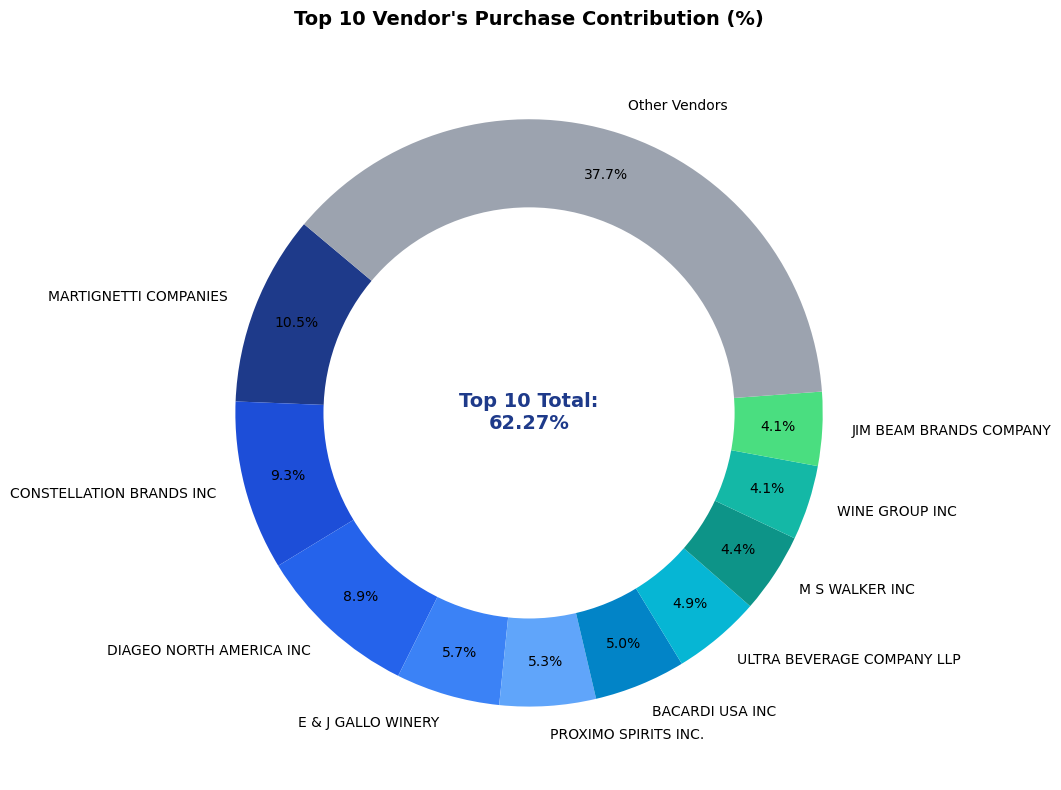

In [26]:
# 1. Ensure Top_vendors values are properly extracted as percentages (0-100 scale)
# If Purchase_Contribution% is already on a 0-100 scale, don't multiply by 100 again.
raw_contributions = Top_vendors["Purchase_Contribution%"].values
# If values are decimals (e.g. 0.6227), convert to %; if already %, use as is:
if raw_contributions.max() <= 1.0:
    purchase_contributions = [c * 100 for c in raw_contributions]
else:
    purchase_contributions = list(raw_contributions)
vendor = list(Top_vendors["VendorName"].values)

# 2. Calculate Top 10 Total & Remaining Contribution safely
total_contribution = sum(purchase_contributions)
remaining_contribution = max(0, 100 - total_contribution)

# 3. Create combined lists for plotting
plot_vendors = vendor + ["Other Vendors"]
plot_contributions = purchase_contributions + [remaining_contribution]

# 4. Color Palette using #1E3A8A theme
palette_shades = [
    "#1E3A8A",
    "#1D4ED8",
    "#2563EB",
    "#3B82F6",
    "#60A5FA",
    "#0284C7",
    "#06B6D4",
    "#0D9488",
    "#14B8A6",
    "#4ADE80",
    "#9CA3AF",
]

# 5. Donut Chart Plotting
fig, ax = plt.subplots(figsize=(10, 8))
wedges, texts, autotexts = ax.pie(
    plot_contributions,
    labels=plot_vendors,
    autopct="%1.1f%%",
    startangle=140,
    pctdistance=0.85,
    colors=palette_shades[: len(plot_contributions)],
)

# 6. Draw White Center Circle
centre_circle = plt.Circle((0, 0), 0.70, fc="white")
ax.add_artist(centre_circle)

# 7. Add Center Text Annotation
ax.text(
    0,
    0,
    f"Top 10 Total:\n{total_contribution:.2f}%",
    fontsize=14,
    fontweight="bold",
    ha="center",
    va="center",
    color="#1E3A8A",
)

plt.title(
    "Top 10 Vendor's Purchase Contribution (%)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.tight_layout()
plt.show()

In [27]:
#To analyze the impact of bluk purchaseing on unit costs and profitability.
df['unitPurchasePrice'] = df['TotalPurchaseDollars']/df['TotalPurchaseQuantity']
df['Ordersize'] = pd.qcut(df['TotalPurchaseQuantity'],q=3,labels =['small','Medium','large'])
df.groupby('Ordersize')[['unitPurchasePrice']].mean()

,unitPurchasePrice
Ordersize,
small,45.868871
Medium,13.369569
large,8.520041


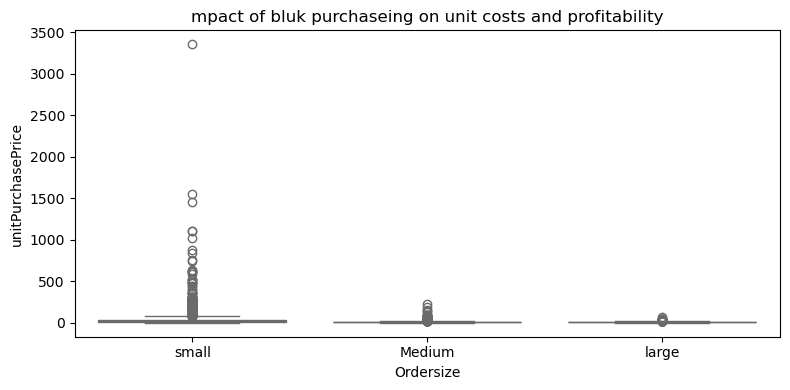

In [28]:
plt.figure(figsize=(8,4))
sns.boxplot(data = df,x='Ordersize',y='unitPurchasePrice',palette ='Set3')
plt.title("mpact of bluk purchaseing on unit costs and profitability")
plt.xlabel("Ordersize")
plt.ylabel("unitPurchasePrice")
plt.tight_layout()
plt.show()

There is a strong inverse relationship between order size and unit purchase price.

Small Orders: Highest average unit price at $45.87.

Medium Orders: Drops significantly to $13.37 (~70.8% savings compared to small orders).

Large Orders: Drops further to $8.52 (~81.4% overall savings compared to small orders).

In [29]:
#Are we keeping too much or too little inventory?
df[df['StockTurnover'] < 1 ].groupby('VendorName')[['StockTurnover']].mean().sort_values('StockTurnover',ascending = True).head(10)

,StockTurnover
VendorName,
TY KU LLC,0.644182
THE IMPORTED GRAPE LLC,0.660236
WEIN BAUER INC,0.666667
Dunn Wine Brokers,0.666667
"PREMIUM PORT WINES, INC.",0.669770
STELLAR IMPORTING CO LLC,0.685185
SURVILLE ENTERPRISES CORP,0.690377
ALISA CARR BEVERAGES,0.691667
JEWELL TOWNE VINEYARDS,0.696749


In [30]:
#Are our prices helping us make a good profit?
df['UnSoldinventoryValue'] = (df['TotalPurchaseQuantity']-df["TotalSalesQuantity"])*df["PurchasePrice"]
print('Total unsold capital:',format_dollar(df['UnSoldinventoryValue'].sum()))

Total unsold capital: 263.96M


In [31]:
inventory_value_per_vendor = df.groupby("VendorName")["UnSoldinventoryValue"].sum().reset_index()

In [32]:
inventory_value_per_vendor = inventory_value_per_vendor.sort_values(by="UnSoldinventoryValue",ascending = False)
inventory_value_per_vendor["UnSoldinventoryValue"] = inventory_value_per_vendor['UnSoldinventoryValue'].apply(format_dollar)
inventory_value_per_vendor.head(10)

,VendorName,UnSoldinventoryValue
16,CONSTELLATION BRANDS INC,30.92M
48,MARTIGNETTI COMPANIES,26.53M
21,DIAGEO NORTH AMERICA INC,21.04M
25,E & J GALLO WINERY,18.47M
100,WINE GROUP INC,13.93M
64,PROXIMO SPIRITS INC.,13.60M
45,M S WALKER INC,12.55M
3,BACARDI USA INC,9.39M
91,ULTRA BEVERAGE COMPANY LLP,9.15M
38,JIM BEAM BRANDS COMPANY,8.76M


In [33]:
top_threshold = df['TotalSalesDollars'].quantile(0.75)
low_threshold =df['TotalSalesDollars'].quantile(0.25)


In [34]:
top_vendors =  df[df['TotalSalesDollars'] >= top_threshold]['profitMargin'].dropna()
low_vendors = df[df['TotalSalesDollars'] <= low_threshold] ['profitMargin'].dropna()


In [35]:
def confidence_interval(data,confidence = 0.95):
    mean_val = np.mean(data)
    std_err = np.std(data,ddof=1)/np.sqrt(len(data))
    t_critical = stats.t.ppf((1+confidence)/2, df = len(data) -1)
    margin_of_error = t_critical * std_err
    return mean_val,mean_val- margin_of_error,mean_val+ margin_of_error 

Top Vendors 95% CI: (15.05, 16.70), Mean: 15.88
Low Vendors 95% CI: (43.62, 46.57), Mean: 45.10


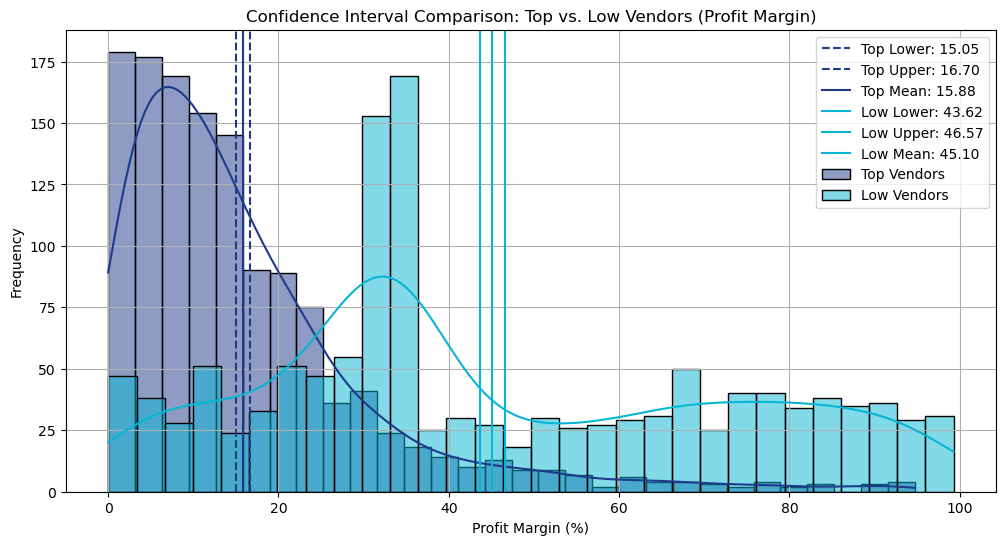

In [36]:
top_mean, top_lower, top_upper = confidence_interval(top_vendors)
low_mean, low_lower, low_upper = confidence_interval(low_vendors)
print(f"Top Vendors 95% CI: ({top_lower:.2f}, {top_upper:.2f}), Mean: {top_mean:.2f}")
print(f"Low Vendors 95% CI: ({low_lower:.2f}, {low_upper:.2f}), Mean: {low_mean:.2f}")
plt.figure(figsize=(12, 6))

primary_color = "#1E3A8A"
secondary_color = "#06B6D4"
# Top Vendors Plot
sns.histplot(top_vendors, kde = True, color=primary_color, bins = 30, alpha=0.5, label="Top Vendors")
plt.axvline(top_lower, color=primary_color, linestyle="--", label=f"Top Lower: {top_lower:.2f}")
plt.axvline(top_upper, color=primary_color, linestyle="--", label=f"Top Upper: {top_upper:.2f}")
plt.axvline(top_mean, color=primary_color, linestyle="-", label=f"Top Mean: {top_mean:.2f}")
# Low Vendors Plot
sns.histplot(low_vendors, kde =True, color=secondary_color, bins = 30, alpha=0.5, label="Low Vendors")
plt.axvline(low_lower, color=secondary_color, linestyle="-", label=f"Low Lower: {low_lower:.2f}")
plt.axvline(low_upper, color=secondary_color,linestyle="-", label=f"Low Upper: {low_upper:.2f}")
plt.axvline(low_mean, color=secondary_color, linestyle="-", label=f"Low Mean: {low_mean:.2f}")
# Finalize Plot
plt.title("Confidence Interval Comparison: Top vs. Low Vendors (Profit Margin)")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True)
plt.show()

In [37]:
# is ther a significant difference in profit margins between top-perfroming and low-perfroming vendors?

#h0 : there is no significant difference in the mean profit margins of top -perfroming and low perfroming vendors.
#h1 :  the mean profit margins of top perfroming  and low perfroming vendor are significantly different.

t_stat,p_value = ttest_ind(top_vendors, low_vendors,equal_var = False)

print(f"T-Statitics:{t_stat:.4f},P-Value:{p_value:.4f}")
if p_value < 0.05:
    print("Reject H0 : There is a significant diference in  the profit margin of top and low perfromaing vendors")
else:
    print("Fall to Reject H0: No significant differnce seen")



T-Statitics:-33.9445,P-Value:0.0000
Reject H0 : There is a significant diference in  the profit margin of top and low perfromaing vendors
